<a href="https://colab.research.google.com/github/nagamkavyalakshmi/project--1-traffic-prediction/blob/main/Ai_Based_traffic_Density_prediction_Project_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Install the python libraries
!pip install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
#Creating a Traffic Dataset
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

data = pd.DataFrame({
    "hour": np.random.randint(0, 24, n),
    "day": np.random.randint(0, 7, n),
    "vehicles": np.random.randint(20, 600, n),
    "temperature": np.random.randint(20, 40, n),
    "rainfall": np.random.randint(0, 20, n)
})

def traffic_level(row):
    vehicles = row["vehicles"]
    hour = row["hour"]

    if vehicles >= 400 or (7 <= hour <= 9 and vehicles >= 250) or (17 <= hour <= 20 and vehicles >= 250):
        return "High"
    elif vehicles >= 200:
        return "Medium"
    else:
        return "Low"

data["traffic"] = data.apply(traffic_level, axis=1)

print(data.head())

   hour  day  vehicles  temperature  rainfall traffic
0     6    6       405           27         0    High
1    19    0       363           22        13    High
2    14    1       414           23         1    High
3    10    5        83           34         3     Low
4     7    5        91           25        18     Low


In [ ]:
# Analyze The Dataset
# checking the dataset
print(data.shape)
print(data.info())
print(data.describe())
print(data.isnull().sum())

(1000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   hour         1000 non-null   int64 
 1   day          1000 non-null   int64 
 2   vehicles     1000 non-null   int64 
 3   temperature  1000 non-null   int64 
 4   rainfall     1000 non-null   int64 
 5   traffic      1000 non-null   object
dtypes: int64(5), object(1)
memory usage: 47.0+ KB
None
              hour          day     vehicles  temperature     rainfall
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000
mean     11.432000     2.978000   309.536000    29.547000     9.810000
std       7.147199     2.003879   165.576739     5.733818     5.762561
min       0.000000     0.000000    20.000000    20.000000     0.000000
25%       5.000000     1.000000   167.000000    24.000000     5.000000
50%      12.000000     3.000000   308.000000    30.000000    10.000000
75% 

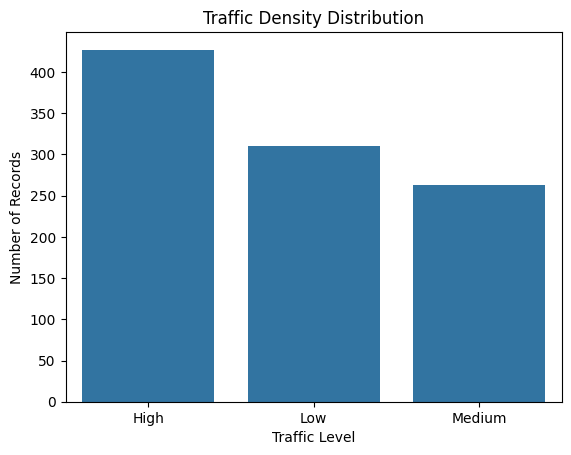

In [ ]:
# Traffic density  distribution Graph
sns.countplot(x="traffic", data=data)
plt.title("Traffic Density Distribution")
plt.xlabel("Traffic Level")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
# Preparing data for ML
data["traffic_encoded"] = data["traffic"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})

X = data[[
    "hour",
    "day",
    "vehicles",
    "temperature",
    "rainfall"
]]

y = data["traffic_encoded"]  # y represents output : Low/medium /High

In [ ]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 5)
Testing data: (200, 5)


In [ ]:
# Here Training = 80%
# Testing = 20%

In [ ]:
# Train the AI Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Test The Model
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.99


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Low", "Medium", "High"]
))

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        62
      Medium       0.96      1.00      0.98        53
        High       1.00      0.98      0.99        85

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



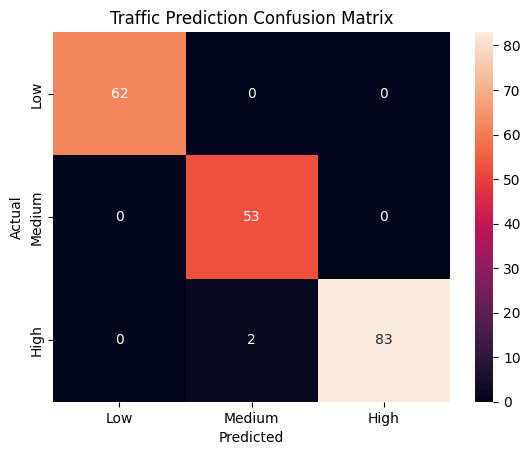

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Traffic Prediction Confusion Matrix")
plt.show()

In [ ]:
# Making my own prediction
# Suppose:
# Time = 8 AM
# Monday = 0
# Vehicles = 450
# Temperature = 28°C
# Rainfall = 2 mm
new_data = pd.DataFrame({
    "hour": [8],
    "day": [0],
    "vehicles": [450],
    "temperature": [28],
    "rainfall": [2]
})

prediction = model.predict(new_data)

labels = {
    0: "Low Traffic Density",
    1: "Medium Traffic Density",
    2: "High Traffic Density"
}

print("Predicted Traffic:", labels[prediction[0]])

Predicted Traffic: High Traffic Density
